# 04 · Preprocesamiento: de tasas observadas a matrices para el agrupamiento

**Entrada:** `data/processed/base_municipal_2022_2025.csv` (notebook 03).

**Salida:** matrices *municipio × variable* listas para los algoritmos de agrupamiento (`data/processed/matrices/`).

## Decisiones que vienen del análisis exploratorio

| Hallazgo del EDA | Decisión en este notebook |
|---|---|
| Los conteos dependen del tamaño de la población | Trabajar con **tasas** por 100 mil habitantes (ya construidas en el 03). |
| En municipios pequeños, los delitos poco frecuentes producen tasas ruidosas e inestables (embudo y estabilidad interanual) | **Suavizado bayesiano empírico** de las tasas. |
| Las tasas son muy asimétricas | Transformación **log(1 + x)**. |
| Variables en escalas muy distintas (hurto ≈ 160 frente a violación c. esp. ≈ 1 por 100 mil) | **Escalado** para que cada delito pese lo mismo en las distancias. |
| Bloque patrimonial + extorsión muy correlacionado | Evaluar una representación con **componentes principales (PCA)**. |

Se mantienen los **12 delitos** del protocolo.

## 0. Configuración

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / "src").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from IPython.display import display

from src.utilidades import (
    RUTA_PROCESSED, ANIOS_ESTUDIO, DELITOS, CODIGOS_DELITO, CODIGO_A_CORTO,
    FAMILIA_DELITO, COLOR, COLOR_FAMILIA, CMAP_DIVERGENTE, configurar_estilo,
    subtitulo, fuente, guardar_figura,
)
from src.preprocesamiento import suavizado_bayes_empirico

configurar_estilo()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

CARPETA_FIG = "04_preprocesamiento"
FUENTE = "Fuente: elaboración propia con datos del MP (denuncias) e INE (población)."
SEMILLA = 42
COLOR_DELITO = {DELITOS[d]: COLOR_FAMILIA[FAMILIA_DELITO[d]] for d in DELITOS}
RUTA_MATRICES = RUTA_PROCESSED / "matrices"
RUTA_MATRICES.mkdir(parents=True, exist_ok=True)

## 1. Carga de datos

Además de la base municipal se necesitan:

- La **exposición**: población acumulada 2022–2025 (persona-años), que es el denominador de la tasa del periodo.
- Los **conteos anuales**, para validar el suavizado con la estabilidad año a año.

In [2]:
base = pd.read_csv(RUTA_PROCESSED / "base_municipal_2022_2025.csv",
                   encoding="utf-8-sig").set_index("Codigo_Municipio")

poblacion = pd.read_csv(RUTA_PROCESSED / "poblacion_municipal_2015_2035.csv", encoding="utf-8-sig")
poblacion = poblacion[poblacion["Anio"].isin(ANIOS_ESTUDIO)]
exposicion = poblacion.groupby("Codigo_Municipio")["Poblacion"].sum().reindex(base.index)
pob_anual = poblacion.pivot_table(index="Codigo_Municipio", columns="Anio", values="Poblacion")

conteos = base[[f"n_{c}" for c in CODIGOS_DELITO]].set_axis(CODIGOS_DELITO, axis=1)
tasas_obs = base[[f"tasa_{c}" for c in CODIGOS_DELITO]].set_axis(CODIGOS_DELITO, axis=1)

# Conteos anuales con el código INE (el CSV de denuncias usa los nombres del MP)
den = pd.read_csv(RUTA_PROCESSED / "denuncias_municipio_anio_delito.csv", encoding="utf-8-sig")
llave = base.reset_index()[["Codigo_Municipio", "Departamento", "Municipio_MP"]]
den = den.merge(llave, left_on=["Departamento", "Municipio"],
                right_on=["Departamento", "Municipio_MP"], how="left", validate="many_to_one")
assert den["Codigo_Municipio"].notna().all()
conteos_anuales = den.pivot_table(index=["Codigo_Municipio", "Anio"], columns="Codigo_Delito",
                                  values="Denuncias", aggfunc="sum")[CODIGOS_DELITO]

print(f"Municipios: {len(base)}   Delitos: {len(CODIGOS_DELITO)}")
print(f"¿Tasas reproducibles desde conteos y exposición? "
      f"{np.allclose(conteos.div(exposicion, axis=0) * 1e5, tasas_obs)}")

Municipios: 340   Delitos: 12
¿Tasas reproducibles desde conteos y exposición? True


## 2. Suavizado bayesiano empírico

### 2.1 Idea

La tasa de un municipio de 3,000 habitantes con **una** denuncia de violación agravada es de 8 por 100 mil, casi tres veces la nacional. Con **cero** denuncias sería 0. Ninguno de los dos valores es una buena estimación del riesgo real: hay muy poca información.

El **suavizado bayesiano empírico** combina la tasa propia del municipio con la tasa nacional, dándole más peso a la propia cuanto más información tiene (más población y delito más frecuente):

$$\hat{\theta}_i = m + w_i\,(r_i - m), \qquad w_i = \frac{A}{A + m / n_i}$$

- $r_i$: tasa observada del municipio; $m$: tasa nacional; $n_i$: persona-años.
- $A$: varianza **real** entre municipios, estimada como la varianza observada menos la parte atribuible al azar ($A = s^2 - m/\bar{n}$). Estimador de momentos de Marshall (1991).
- $w_i \in [0, 1]$: **peso** de la tasa propia. Si $w_i \approx 1$ la tasa casi no cambia.

Se aplica por separado a cada delito. Es una técnica estándar en epidemiología y análisis delictivo para mapear tasas de áreas pequeñas.

In [3]:
resultados_eb = {c: suavizado_bayes_empirico(conteos[c], exposicion) for c in CODIGOS_DELITO}
tasas_eb = pd.DataFrame({c: r["tasa_suavizada"] for c, r in resultados_eb.items()})
pesos = pd.DataFrame({c: r["peso"] for c, r in resultados_eb.items()})

parametros_eb = pd.DataFrame({
    "Tasa nacional (m)": {c: r.attrs["tasa_global"] for c, r in resultados_eb.items()},
    "Varianza real (A)": {c: r.attrs["varianza_A"] for c, r in resultados_eb.items()},
    "Peso mediano": pesos.median(),
    "Peso mínimo": pesos.min(),
    "% municipios con peso < 0.5": (pesos < 0.5).mean() * 100,
    "Cambio absoluto mediano (%)": ((tasas_eb - tasas_obs).abs() / tasas_obs.replace(0, np.nan)).median() * 100,
}).rename(index=CODIGO_A_CORTO).sort_values("Peso mediano", ascending=False)
display(parametros_eb.round(2))

,Tasa nacional (m),Varianza real (A),Peso mediano,Peso mínimo,% municipios con peso < 0.5,Cambio absoluto mediano (%)
Robo,87.01,"24,283.29",1.00,0.97,0.00,1.06
Hurto,159.69,"42,883.08",1.00,0.97,0.00,0.43
Robo agravado,92.41,"18,328.19",1.00,0.96,0.00,0.99
Hurto agravado,87.24,"10,324.93",0.99,0.93,0.00,1.03
Extorsión,119.35,"12,795.63",0.99,0.92,0.00,0.57
Homicidio,19.49,345.32,0.96,0.66,0.00,4.68
Asesinato,4.84,29.31,0.89,0.40,0.59,9.41
Violación,25.30,109.26,0.85,0.32,1.47,4.50
Agresión sexual,12.69,48.15,0.83,0.29,1.76,6.56
Violación c. esp. agrav.,1.22,3.54,0.79,0.24,5.29,8.40


Como se esperaba, en los delitos frecuentes el peso es prácticamente **1** (el suavizado casi no toca las tasas). En los delitos sexuales agravados, el peso mediano baja a entre 0.67 y 0.79, y en 1 de cada 5 municipios la tasa propia pesa menos que la nacional.

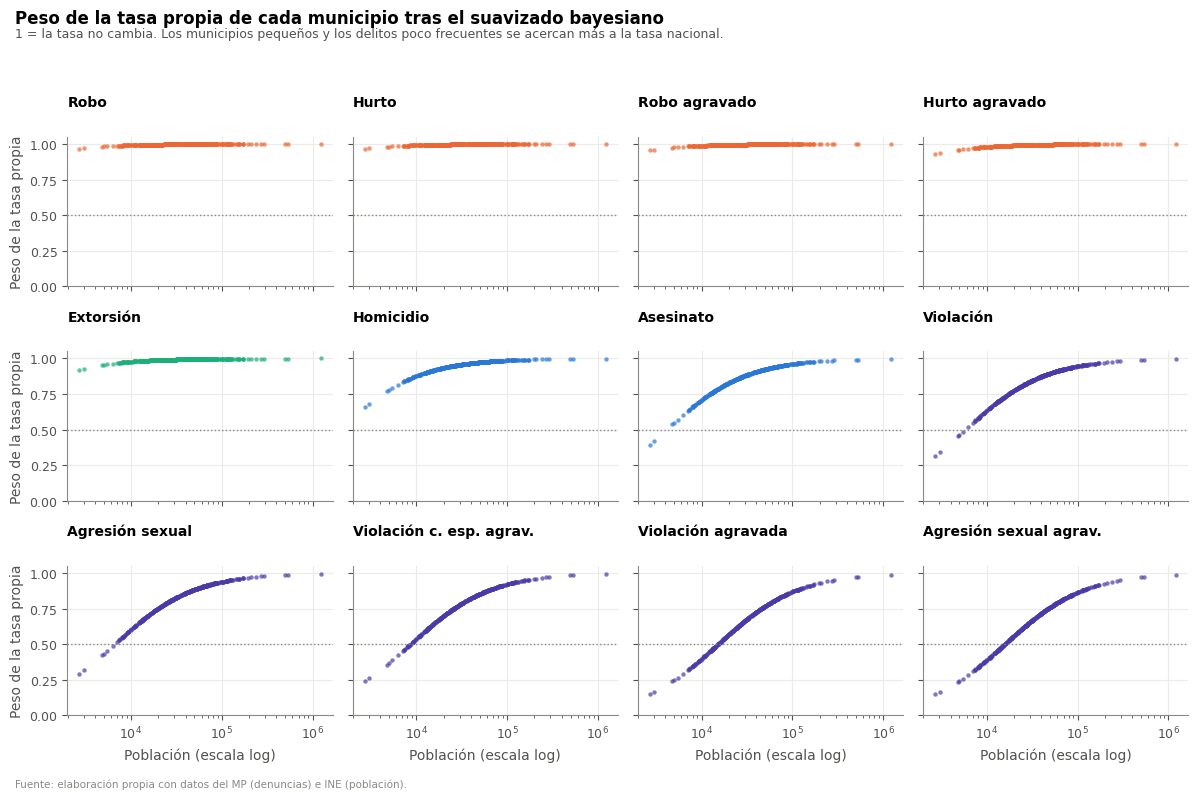

In [4]:
fig, axes = plt.subplots(3, 4, figsize=(12, 8), sharex=True, sharey=True)
for ax, c in zip(axes.flat, pesos[pesos.columns].median().sort_values(ascending=False).index):
    ax.scatter(exposicion / 4, pesos[c], s=10, color=COLOR_DELITO[c], alpha=0.7)
    ax.axhline(0.5, color=COLOR["gris"], linestyle=":", linewidth=1)
    ax.set_xscale("log")
    ax.set_ylim(0, 1.05)
    ax.set_title(CODIGO_A_CORTO[c], fontsize=10)
for ax in axes[-1]:
    ax.set_xlabel("Población (escala log)")
for ax in axes[:, 0]:
    ax.set_ylabel("Peso de la tasa propia")
fig.suptitle("Peso de la tasa propia de cada municipio tras el suavizado bayesiano",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.text(0.01, 0.945, "1 = la tasa no cambia. Los municipios pequeños y los delitos poco "
         "frecuentes se acercan más a la tasa nacional.", fontsize=9, color=COLOR["texto_sec"])
fuente(fig, FUENTE)
fig.tight_layout(rect=(0, 0.02, 1, 0.93))
guardar_figura(fig, "01_pesos_suavizado", CARPETA_FIG)
plt.show()

### 2.2 Efecto visual del suavizado

Se comparan las tasas observadas y suavizadas frente a la población para dos delitos frecuentes y dos poco frecuentes.

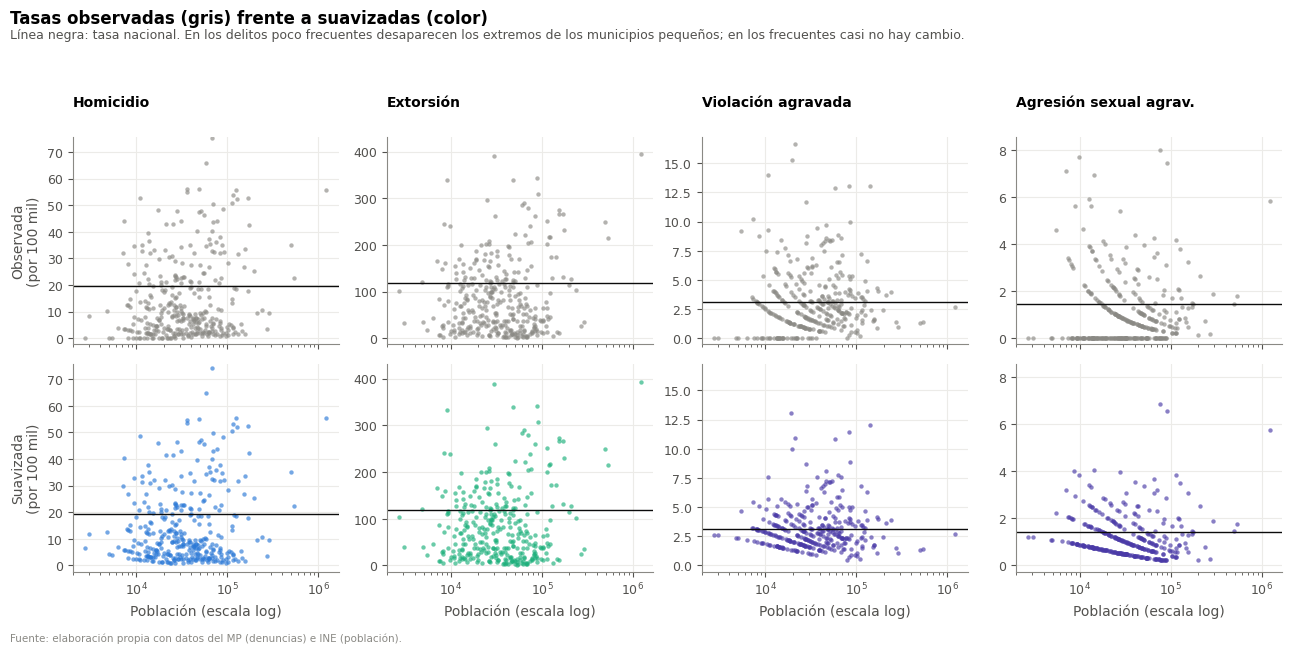

In [5]:
ejemplos = ["homicidio", "extorsion", "violacion_agravada", "agresion_sexual_agravada"]
fig, axes = plt.subplots(2, 4, figsize=(13, 6.5), sharex=True)
for j, c in enumerate(ejemplos):
    ymax = tasas_obs[c].quantile(0.995) * 1.1
    for i, (tabla, nombre) in enumerate([(tasas_obs, "Observada"), (tasas_eb, "Suavizada")]):
        ax = axes[i, j]
        ax.scatter(exposicion / 4, tabla[c], s=10, alpha=0.65,
                   color=COLOR["gris"] if i == 0 else COLOR_DELITO[c])
        ax.axhline(resultados_eb[c].attrs["tasa_global"], color=COLOR["texto"], linewidth=1)
        ax.set_xscale("log")
        ax.set_ylim(-ymax * 0.03, ymax)
        if i == 0:
            ax.set_title(CODIGO_A_CORTO[c], fontsize=10)
        if j == 0:
            ax.set_ylabel(f"{nombre}\n(por 100 mil)")
        if i == 1:
            ax.set_xlabel("Población (escala log)")
fig.suptitle("Tasas observadas (gris) frente a suavizadas (color)", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.text(0.01, 0.935, "Línea negra: tasa nacional. En los delitos poco frecuentes desaparecen los "
         "extremos de los municipios pequeños; en los frecuentes casi no hay cambio.",
         fontsize=9, color=COLOR["texto_sec"])
fuente(fig, FUENTE)
fig.tight_layout(rect=(0, 0.02, 1, 0.92))
guardar_figura(fig, "02_observada_vs_suavizada", CARPETA_FIG)
plt.show()

Las "curvas" que aparecen en las tasas suavizadas de los delitos poco frecuentes son los municipios con **cero denuncias**: en lugar de quedar en 0 (una estimación poco creíble), reciben una tasa baja que depende de su población. Cuanto más pequeño es el municipio, menos evidencia aporta su cero y más se acerca a la tasa nacional.

### 2.3 Validación: ¿el suavizado mejora la calidad de las tasas?

Un buen suavizado debe (a) **conservar el orden** de los municipios en los delitos con mucha información y (b) **aumentar la estabilidad** año a año en los delitos ruidosos. Para (b) se suaviza cada año por separado con el mismo método y se compara la correlación de Spearman entre años consecutivos.

In [6]:
def estabilidad(tabla_anual):
    """Spearman promedio entre años consecutivos, por delito."""
    valores = {}
    for c in CODIGOS_DELITO:
        rhos = [stats.spearmanr(tabla_anual.xs(a1, level="Anio")[c],
                                tabla_anual.xs(a2, level="Anio")[c])[0]
                for a1, a2 in zip(ANIOS_ESTUDIO[:-1], ANIOS_ESTUDIO[1:])]
        valores[c] = np.mean(rhos)
    return pd.Series(valores)

tasa_anual_obs, tasa_anual_eb = [], []
for anio in ANIOS_ESTUDIO:
    cont = conteos_anuales.xs(anio, level="Anio").reindex(base.index)
    expo = pob_anual[anio].reindex(base.index)
    obs = cont.div(expo, axis=0) * 1e5
    eb = pd.DataFrame({c: suavizado_bayes_empirico(cont[c], expo)["tasa_suavizada"]
                       for c in CODIGOS_DELITO})
    tasa_anual_obs.append(obs.assign(Anio=anio).set_index("Anio", append=True))
    tasa_anual_eb.append(eb.assign(Anio=anio).set_index("Anio", append=True))
tasa_anual_obs = pd.concat(tasa_anual_obs)
tasa_anual_eb = pd.concat(tasa_anual_eb)

validacion = pd.DataFrame({
    "Orden conservado (ρ observada vs suavizada)":
        {c: stats.spearmanr(tasas_obs[c], tasas_eb[c])[0] for c in CODIGOS_DELITO},
    "Estabilidad interanual, observada": estabilidad(tasa_anual_obs),
    "Estabilidad interanual, suavizada": estabilidad(tasa_anual_eb),
})
validacion["Mejora de estabilidad"] = (validacion["Estabilidad interanual, suavizada"]
                                       - validacion["Estabilidad interanual, observada"])
validacion = validacion.rename(index=CODIGO_A_CORTO).sort_values("Estabilidad interanual, observada")
display(validacion.round(2))

,Orden conservado (ρ observada vs suavizada),"Estabilidad interanual, observada","Estabilidad interanual, suavizada",Mejora de estabilidad
Violación c. esp. agrav.,0.94,0.22,0.32,0.11
Violación agravada,0.97,0.22,0.26,0.04
Agresión sexual agrav.,0.90,0.25,0.41,0.16
Agresión sexual,0.99,0.44,0.55,0.12
Asesinato,0.92,0.45,0.52,0.07
Violación,0.99,0.51,0.56,0.05
Homicidio,0.99,0.70,0.76,0.06
Robo,1.00,0.73,0.74,0.01
Robo agravado,1.00,0.83,0.85,0.02
Hurto agravado,1.00,0.86,0.87,0.01


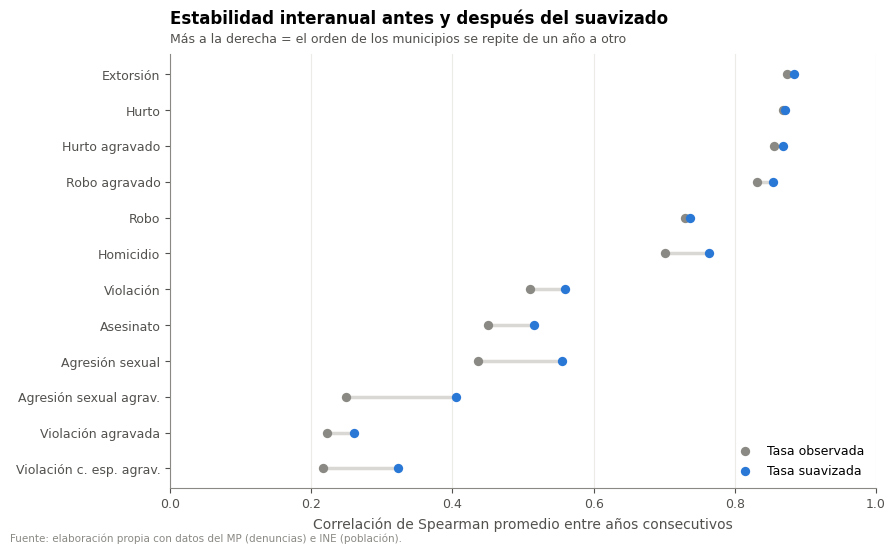

In [7]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for i, d in enumerate(validacion.index):
    ax.plot(validacion.loc[d, ["Estabilidad interanual, observada",
                               "Estabilidad interanual, suavizada"]], [i, i],
            color=COLOR["gris_claro"], linewidth=2.5, zorder=1)
ax.scatter(validacion["Estabilidad interanual, observada"], range(12), s=45,
           color=COLOR["gris"], zorder=2, label="Tasa observada")
ax.scatter(validacion["Estabilidad interanual, suavizada"], range(12), s=45,
           color=COLOR["azul"], zorder=3, label="Tasa suavizada")
ax.set_yticks(range(12), validacion.index)
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Correlación de Spearman promedio entre años consecutivos")
ax.set_title("Estabilidad interanual antes y después del suavizado")
subtitulo(ax, "Más a la derecha = el orden de los municipios se repite de un año a otro")
ax.legend(loc="lower right")
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "03_estabilidad_suavizado", CARPETA_FIG)
plt.show()

## 3. Transformación logarítmica

Se aplica $\log(1 + x)$ a las tasas suavizadas. Se usa $1 + x$ para que la transformación esté definida aun si una tasa fuera cero, y porque en tasas por 100 mil no distorsiona los valores relevantes. Así se reduce la asimetría y los municipios con tasas muy altas no dominan las distancias.

In [8]:
log_eb = np.log1p(tasas_eb)
asimetria = pd.DataFrame({
    "Observada": tasas_obs.apply(stats.skew),
    "Suavizada": tasas_eb.apply(stats.skew),
    "log(1 + suavizada)": log_eb.apply(stats.skew),
}).rename(index=CODIGO_A_CORTO)
display(asimetria.round(2))
print(f"Asimetría absoluta máxima tras la transformación: {asimetria['log(1 + suavizada)'].abs().max():.2f}")

,Observada,Suavizada,log(1 + suavizada)
Homicidio,1.55,1.60,0.12
Asesinato,2.04,2.26,0.71
Robo,5.94,5.96,0.26
Robo agravado,3.12,3.13,-0.03
Hurto,3.19,3.20,0.05
Hurto agravado,2.40,2.36,-0.15
Extorsión,1.41,1.42,-0.54
Violación,0.64,0.62,-0.35
Violación agravada,1.99,1.98,0.59
Violación c. esp. agrav.,3.82,4.91,1.16


Asimetría absoluta máxima tras la transformación: 1.16


Todas las variables quedan con asimetría absoluta ≤ 1.2 (antes, hasta 5.9). Los delitos sexuales agravados quedan con una leve cola a la derecha, esperable porque el suavizado eliminó los ceros y concentró los valores cerca de la tasa nacional.

## 4. Escalado

Los algoritmos de agrupamiento usan distancias, así que una variable con mayor rango pesaría más. Se comparan dos escaladores:

- **`StandardScaler`**: resta la media y divide entre la desviación estándar. Todas las variables quedan con varianza 1, es decir, **mismo peso**.
- **`RobustScaler`**: resta la mediana y divide entre el rango intercuartílico. Es menos sensible a valores extremos, pero las variables **no** quedan con la misma varianza.

In [9]:
X_std = pd.DataFrame(StandardScaler().fit_transform(log_eb), index=log_eb.index, columns=CODIGOS_DELITO)
X_rob = pd.DataFrame(RobustScaler().fit_transform(log_eb), index=log_eb.index, columns=CODIGOS_DELITO)

comparacion = pd.DataFrame({
    "Desv. est. (Standard)": X_std.std(ddof=0),
    "Máx |valor| (Standard)": X_std.abs().max(),
    "Desv. est. (Robust)": X_rob.std(ddof=0),
    "Máx |valor| (Robust)": X_rob.abs().max(),
}).rename(index=CODIGO_A_CORTO)
display(comparacion.round(2))
peso_rob = X_rob.var(ddof=0) / X_rob.var(ddof=0).sum() * 100
print(f"Con RobustScaler, la variable con más peso aporta {peso_rob.max():.1f} % de la varianza total "
      f"y la de menos, {peso_rob.min():.1f} % (con StandardScaler todas aportan {100/12:.1f} %).")

,Desv. est. (Standard),Máx |valor| (Standard),Desv. est. (Robust),Máx |valor| (Robust)
Homicidio,1.00,2.34,0.62,1.49
Asesinato,1.00,3.16,0.70,2.33
Robo,1.00,3.47,0.75,2.67
Robo agravado,1.00,2.39,0.68,1.64
Hurto,1.00,2.91,0.79,2.32
Hurto agravado,1.00,2.35,0.72,1.75
Extorsión,1.00,3.26,0.70,2.40
Violación,1.00,3.27,0.70,2.32
Violación agravada,1.00,3.32,0.78,2.65
Violación c. esp. agrav.,1.00,4.87,0.75,3.83


Con RobustScaler, la variable con más peso aporta 10.0 % de la varianza total y la de menos, 6.1 % (con StandardScaler todas aportan 8.3 %).


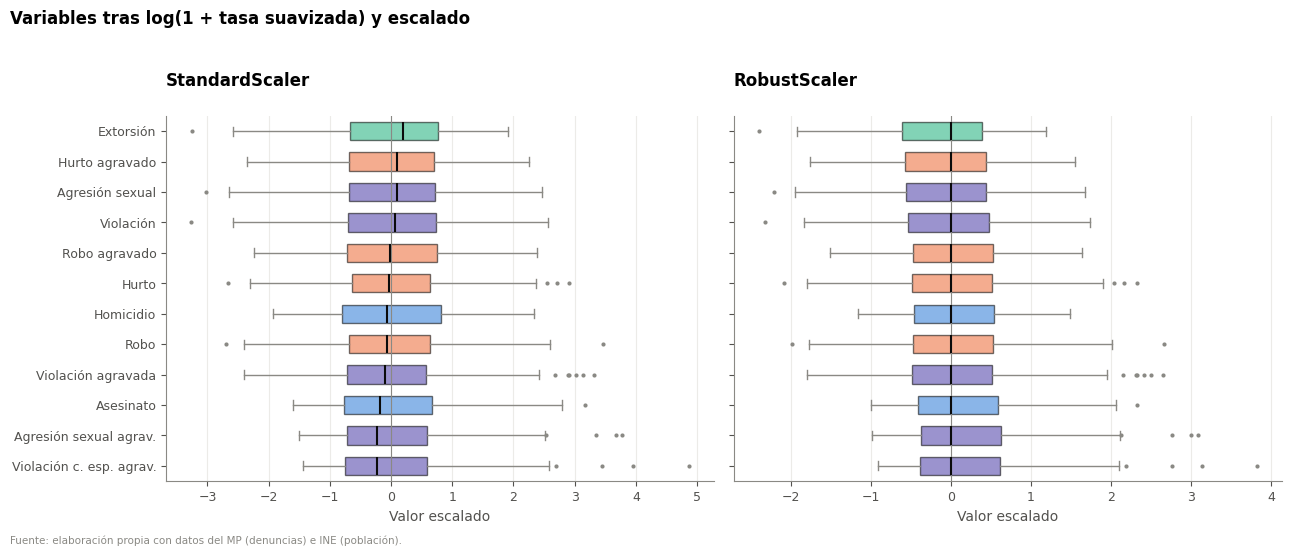

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
orden = X_std.median().sort_values().index
for ax, (X, nombre) in zip(axes, [(X_std, "StandardScaler"), (X_rob, "RobustScaler")]):
    bp = ax.boxplot([X[c] for c in orden], vert=False, patch_artist=True, widths=0.6,
                    medianprops=dict(color=COLOR["texto"], linewidth=1.5),
                    flierprops=dict(marker="o", markersize=3, markerfacecolor=COLOR["gris"],
                                    markeredgecolor="none"),
                    whiskerprops=dict(color=COLOR["gris"]), capprops=dict(color=COLOR["gris"]))
    for caja, c in zip(bp["boxes"], orden):
        caja.set_facecolor(COLOR_DELITO[c]); caja.set_alpha(0.55)
    ax.axvline(0, color=COLOR["gris"], linewidth=0.8)
    ax.set_yticks(range(1, 13), [CODIGO_A_CORTO[c] for c in orden])
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Valor escalado")
    ax.set_title(nombre)
fig.suptitle("Variables tras log(1 + tasa suavizada) y escalado", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fuente(fig, FUENTE)
fig.tight_layout(rect=(0, 0.02, 1, 0.95))
guardar_figura(fig, "04_comparacion_escalado", CARPETA_FIG)
plt.show()

**Decisión:** se adopta **`StandardScaler` como escalado principal**.

- Tras la transformación logarítmica ya no quedan valores extremos severos (máximo |z| < 5), que era la principal razón para preferir un escalado robusto.
- Garantiza que los **12 delitos pesen igual** en las distancias. Con `RobustScaler` los pesos quedarían desiguales sin una justificación teórica.

La versión con `RobustScaler` se guarda como **análisis de sensibilidad**, para comprobar en la etapa de modelado que los resultados no dependen de esta elección.

## 5. Redundancia y componentes principales

El bloque patrimonial + extorsión está muy correlacionado. En una distancia euclidiana, ese bloque cuenta prácticamente como **una misma dimensión repetida varias veces**, lo que puede sesgar los grupos hacia la intensidad patrimonial. El PCA produce componentes **no correlacionadas** que resumen la información sin esa repetición.

In [11]:
corr = X_std.corr(method="spearman")
tri = np.tril_indices(12, -1)
print(f"Pares de delitos con |ρ| ≥ 0.8: {(np.abs(corr.values[tri]) >= 0.8).sum()}")
print(f"Correlación mediana: {np.median(corr.values[tri]):.2f}")

pca = PCA(random_state=SEMILLA).fit(X_std)
varianza = pd.DataFrame({
    "Varianza explicada (%)": pca.explained_variance_ratio_ * 100,
    "Acumulada (%)": np.cumsum(pca.explained_variance_ratio_) * 100,
    "Autovalor": pca.explained_variance_,
}, index=[f"CP{i}" for i in range(1, 13)])
display(varianza.head(7).round(2))

n_kaiser = int((pca.explained_variance_ > 1).sum())
N_COMPONENTES = int(np.argmax(varianza["Acumulada (%)"].values >= 80) + 1)
print(f"Criterio de Kaiser (autovalor > 1): {n_kaiser} componentes "
      f"({varianza['Acumulada (%)'].iloc[n_kaiser - 1]:.1f} %)")
print(f"Criterio del 80 % de varianza:       {N_COMPONENTES} componentes "
      f"({varianza['Acumulada (%)'].iloc[N_COMPONENTES - 1]:.1f} %)")

Pares de delitos con |ρ| ≥ 0.8: 3
Correlación mediana: 0.42


,Varianza explicada (%),Acumulada (%),Autovalor
CP1,50.19,50.19,6.04
CP2,11.25,61.44,1.35
CP3,8.87,70.31,1.07
CP4,6.74,77.05,0.81
CP5,5.95,83.00,0.72
CP6,4.63,87.63,0.56
CP7,3.29,90.93,0.40


Criterio de Kaiser (autovalor > 1): 3 componentes (70.3 %)
Criterio del 80 % de varianza:       5 componentes (83.0 %)


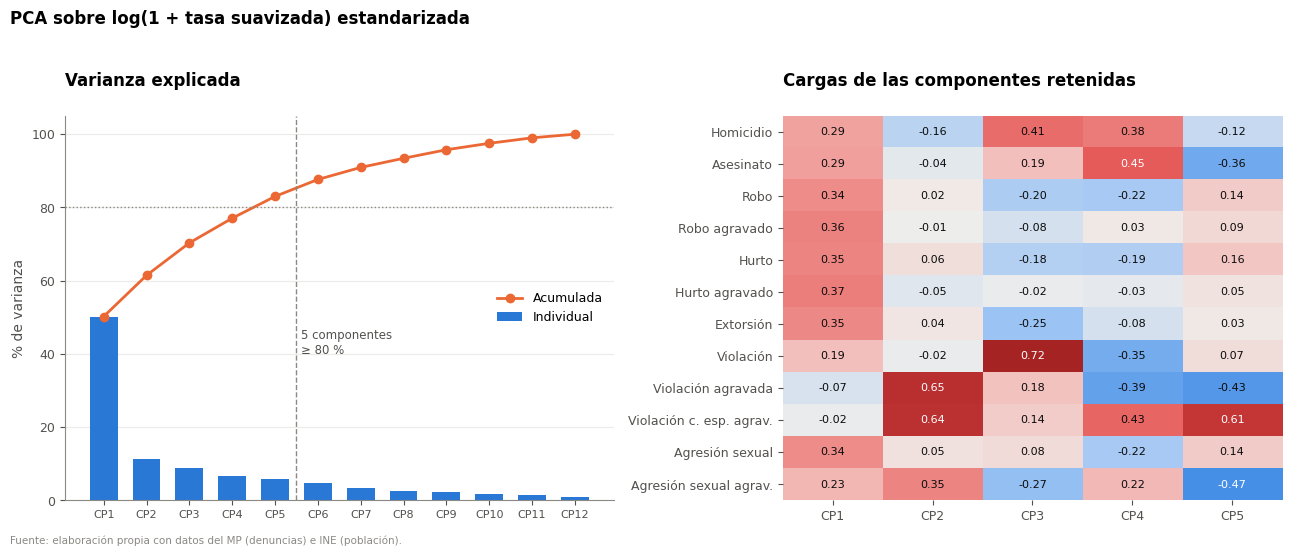

In [12]:
cargas = pd.DataFrame(pca.components_[:N_COMPONENTES].T,
                      index=[CODIGO_A_CORTO[c] for c in CODIGOS_DELITO],
                      columns=[f"CP{i}" for i in range(1, N_COMPONENTES + 1)])

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
ax.bar(range(1, 13), varianza["Varianza explicada (%)"], color=COLOR["azul"], width=0.65,
       label="Individual")
ax.plot(range(1, 13), varianza["Acumulada (%)"], color=COLOR["naranja"], marker="o", label="Acumulada")
ax.axhline(80, color=COLOR["gris"], linestyle=":", linewidth=1)
ax.axvline(N_COMPONENTES + 0.5, color=COLOR["gris"], linestyle="--", linewidth=1)
ax.text(N_COMPONENTES + 0.6, 40, f"{N_COMPONENTES} componentes\n≥ 80 %", fontsize=8.5,
        color=COLOR["texto_sec"])
ax.set_xticks(range(1, 13), [f"CP{i}" for i in range(1, 13)], fontsize=8)
ax.set_ylim(0, 105)
ax.grid(axis="x", visible=False)
ax.set_ylabel("% de varianza")
ax.set_title("Varianza explicada")
ax.legend(loc="center right")

ax = axes[1]
ax.imshow(cargas.values, cmap=CMAP_DIVERGENTE, vmin=-0.75, vmax=0.75, aspect="auto")
ax.set_xticks(range(N_COMPONENTES), cargas.columns)
ax.set_yticks(range(12), cargas.index)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(12):
    for j in range(N_COMPONENTES):
        v = cargas.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.45 else COLOR["texto"])
ax.set_title("Cargas de las componentes retenidas")
fig.suptitle("PCA sobre log(1 + tasa suavizada) estandarizada", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fuente(fig, FUENTE)
fig.tight_layout(rect=(0, 0.02, 1, 0.95))
guardar_figura(fig, "05_pca_final", CARPETA_FIG)
plt.show()

Se retienen las componentes que explican **al menos el 80 %** de la varianza. Es un criterio más conservador que el de Kaiser: pierde menos información de los delitos que no pertenecen al bloque principal.

## 6. Representaciones candidatas

No se decide aquí cuál representación es "la mejor". Eso lo dirán las métricas de validación en la etapa de modelado. Se preparan las siguientes:

| Código | Representación | Uso |
|---|---|---|
| **R1** | log(1 + tasa suavizada) + `StandardScaler` (12 variables) | **Principal** |
| **R2** | Igual que R1 pero con `RobustScaler` | Sensibilidad al escalado |
| **R3** | Componentes principales de R1 (≥ 80 % de varianza) | Sensibilidad a la redundancia |
| **R0** | log(1 + tasa **observada**) + `StandardScaler` | Referencia: mide el efecto del suavizado |

In [13]:
X_pca = pd.DataFrame(pca.transform(X_std)[:, :N_COMPONENTES], index=X_std.index,
                     columns=[f"CP{i}" for i in range(1, N_COMPONENTES + 1)])
X_ref = pd.DataFrame(StandardScaler().fit_transform(np.log1p(tasas_obs)),
                     index=tasas_obs.index, columns=CODIGOS_DELITO)

representaciones = {
    "R1_log_suavizada_standard": X_std,
    "R2_log_suavizada_robust": X_rob,
    "R3_pca": X_pca,
    "R0_log_observada_standard": X_ref,
}

### 6.1 Representaciones alternativas para los delitos poco frecuentes

Los tres delitos sexuales agravados siguen siendo poco estables después del suavizado. Para evaluar en el notebook 05 si conviene **agruparlos** o **excluirlos**, se construyen tres variantes con el mismo procesamiento (suavizado → log → `StandardScaler`):

| Código | Variables | Tratamiento |
|---|---|---|
| **R4a** | 9 | Agrupar **por tipo penal**: *violación total* (simple + agravada + circunstancias especiales) y *agresión sexual total* (simple + agravada). |
| **R4b** | 10 | Agrupar **los tres agravados** en una sola variable: *delitos sexuales agravados*. La violación y la agresión sexual simples quedan separadas. |
| **R5** | 9 | **Excluir** los tres delitos agravados. |

R4a y R4b conservan la información de los 12 delitos (se suman denuncias, no se descarta ninguna). R5 descarta el 0.9 % de las denuncias.

In [14]:
RAROS = ["violacion_agravada", "violacion_circ_especiales", "agresion_sexual_agravada"]

def representar(tabla_conteos):
    """Suavizado bayesiano -> log(1 + x) -> StandardScaler, para una tabla de conteos."""
    suav = pd.DataFrame({c: suavizado_bayes_empirico(tabla_conteos[c], exposicion)["tasa_suavizada"]
                         for c in tabla_conteos.columns})
    return pd.DataFrame(StandardScaler().fit_transform(np.log1p(suav)),
                        index=tabla_conteos.index, columns=tabla_conteos.columns)

conteos_4a = (conteos.drop(columns=RAROS + ["violacion", "agresion_sexual"])
              .assign(violacion_total=conteos[["violacion", "violacion_agravada",
                                               "violacion_circ_especiales"]].sum(axis=1),
                      agresion_sexual_total=conteos[["agresion_sexual",
                                                     "agresion_sexual_agravada"]].sum(axis=1)))
conteos_4b = conteos.drop(columns=RAROS).assign(sexuales_agravados=conteos[RAROS].sum(axis=1))
conteos_5 = conteos.drop(columns=RAROS)

representaciones.update({
    "R4a_agrupada_por_tipo": representar(conteos_4a),
    "R4b_agravados_agrupados": representar(conteos_4b),
    "R5_sin_agravados": representar(conteos_5),
})
print(f"Denuncias de los 3 delitos agravados: {conteos[RAROS].values.sum():,} "
      f"({conteos[RAROS].values.sum() / conteos.values.sum():.1%} del total)")
sa = suavizado_bayes_empirico(conteos_4b["sexuales_agravados"], exposicion)
print(f"Peso mediano del suavizado para 'sexuales agravados' agrupados: {sa['peso'].median():.2f} "
      f"(por separado: {pesos[RAROS].median().round(2).tolist()})")

Denuncias de los 3 delitos agravados: 4,073 (0.9% del total)
Peso mediano del suavizado para 'sexuales agravados' agrupados: 0.74 (por separado: [0.68, 0.79, 0.67])


In [15]:
resumen = []
for nombre, X in representaciones.items():
    assert X.notna().all().all() and np.isfinite(X.values).all()
    assert X.index.equals(base.index)
    X.to_csv(RUTA_MATRICES / f"{nombre}.csv", encoding="utf-8-sig")
    resumen.append({"Representación": nombre, "Filas": X.shape[0], "Columnas": X.shape[1]})
display(pd.DataFrame(resumen))

# Tabla de tasas (observadas, suavizadas y pesos) para la caracterización posterior
tabla_tasas = (base[["Departamento", "Municipio", "Poblacion_prom"]]
               .join(tasas_obs.add_prefix("tasa_obs_"))
               .join(tasas_eb.add_prefix("tasa_eb_"))
               .join(pesos.add_prefix("peso_")))
tabla_tasas.to_csv(RUTA_PROCESSED / "tasas_suavizadas_2022_2025.csv", encoding="utf-8-sig")
print(f"Matrices guardadas en: {RUTA_MATRICES.relative_to(RAIZ)}")
print(f"Tasas suavizadas guardadas en: data/processed/tasas_suavizadas_2022_2025.csv")

,Representación,Filas,Columnas
0,R1_log_suavizada_standard,340,12
1,R2_log_suavizada_robust,340,12
2,R3_pca,340,5
3,R0_log_observada_standard,340,12
4,R4a_agrupada_por_tipo,340,9
5,R4b_agravados_agrupados,340,10
6,R5_sin_agravados,340,9


Matrices guardadas en: data/processed/matrices
Tasas suavizadas guardadas en: data/processed/tasas_suavizadas_2022_2025.csv
